# 03 — Perfis e GMM de usuários

Para cada usuário da amostra, o **perfil** é a média das probabilidades de componente dos livros que ele avaliou, ponderada pela nota. Um segundo **GMM** agrupa esses perfis em segmentos de leitores.

Entrada: `user_interactions.parquet` (gerado por `extract_user_sample.py`), `book_probs.parquet` (notebook 02). Saídas: `user_profiles.parquet`, `user_segments.parquet`, `gmm_users.joblib`.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from recsys import clr, user_profile

SEED = 0
inter = pd.read_parquet('user_interactions.parquet')
book_probs = pd.read_parquet('book_probs.parquet')
K = book_probs.shape[1]
print(f"{inter['user_id'].nunique():,} usuários | {len(inter):,} interações avaliadas | {K} componentes de livro")
inter.groupby('user_id').size().describe().round(1)

50,000 usuários | 8,050,988 interações avaliadas | 20 componentes de livro


count    50000.0
mean       161.0
std        255.0
min         20.0
25%         40.0
50%         82.0
75%        178.0
max       7328.0
dtype: float64

### Perfil de cada usuário

Cálculo vetorizado sobre todas as leituras avaliadas. A função `user_profile` (testada em `test_recsys.py`) é a referência: a célula confere que os dois dão o mesmo resultado.

In [2]:
P = book_probs.reindex(inter['book_id'])
ok = P.notna().all(axis=1).to_numpy()
print(f'{(~ok).sum():,} interações sem livro na tabela de clusters (descartadas)')
inter, P = inter[ok].reset_index(drop=True), P[ok].reset_index(drop=True)

w = inter['rating'].to_numpy(dtype='float32')
num = pd.DataFrame(P.to_numpy() * w[:, None], columns=P.columns).groupby(inter['user_id'].to_numpy()).sum()
profiles = num.div(num.sum(axis=1), axis=0).rename_axis('user_id')
profiles.columns = [f'u_{i}' for i in range(K)]

# conferência contra a função de referência
for u in profiles.index[:25]:
    d = inter[inter['user_id'] == u]
    ref = user_profile(book_probs, d['book_id'].tolist(), d['rating'].tolist())
    assert np.allclose(profiles.loc[u].to_numpy(), ref, atol=1e-4), u
assert not profiles.isna().any().any() and np.allclose(profiles.sum(axis=1), 1, atol=1e-4)
profiles.shape

0 interações sem livro na tabela de clusters (descartadas)


(50000, 20)

### GMM de usuários

Os perfis são proporções (somam 1), portanto não-gaussianos: aplica-se **log-razão centrada** (`clr`) e **PCA** (a clr tem posto K−1) antes do GMM. A escolha de m (nº de segmentos) e do tipo de covariância é por BIC.

componentes PCA: 16


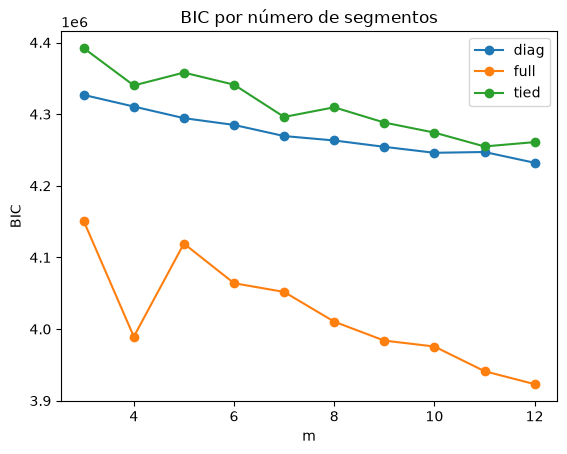

cov,diag,full,tied
m,,,
3,4326843.0,4150812.0,4392152.0
4,4310617.0,3989382.0,4340079.0
5,4294439.0,4119284.0,4358029.0
6,4284965.0,4064017.0,4341160.0
7,4269424.0,4051822.0,4296103.0
8,4263255.0,4010309.0,4309574.0
9,4254380.0,3983869.0,4288272.0
10,4246049.0,3975623.0,4274239.0
11,4247166.0,3941191.0,4254916.0


In [3]:
X = clr(profiles.to_numpy())
pca = PCA(n_components=0.95, random_state=SEED).fit(X)
Z = pca.transform(X)
print('componentes PCA:', pca.n_components_)
rows = []
for cov in ['diag', 'tied', 'full']:
    for m in range(3, 13):
        g = GaussianMixture(m, covariance_type=cov, random_state=SEED, max_iter=200).fit(Z)
        rows.append((cov, m, g.bic(Z), g.converged_))
bic = pd.DataFrame(rows, columns=['cov', 'm', 'bic', 'convergiu'])
for cov, d in bic.groupby('cov'):
    plt.plot(d['m'], d['bic'], marker='o', label=cov)
plt.xlabel('m'); plt.ylabel('BIC'); plt.legend(); plt.title('BIC por número de segmentos'); plt.show()
bic.pivot(index='m', columns='cov', values='bic').round(0)

In [4]:
best = bic.loc[bic['bic'].idxmin()]
COV, M = best['cov'], int(best['m'])
print('menor BIC:', COV, M)

menor BIC: full 12


**Decisão sobre m.** A covariância `full` tem BIC muito menor que `diag` e `tied` em todos os m, e o mínimo cai na borda da busca (m=12) sem cotovelo nítido. Mantemos **m=12 com covariância `full`** como teto de interpretabilidade para segmentos de leitores; a atribuição é suave (probabilidade máxima média ≈ 0,96), então a maioria dos usuários pertence com folga a um segmento. Limitação: m é limitado pelo teto da busca.

In [5]:
pipe = Pipeline([('clr', FunctionTransformer(clr)), ('pca', PCA(n_components=pca.n_components_, random_state=SEED)),
                 ('gmm', GaussianMixture(M, covariance_type=COV, random_state=SEED, max_iter=300, n_init=3))])
pipe.fit(profiles.to_numpy())
print('convergiu:', pipe['gmm'].converged_)
seg = pd.DataFrame(pipe.predict_proba(profiles.to_numpy()).astype('float32'), index=profiles.index,
                   columns=[f's_{i}' for i in range(M)])
assert not seg.isna().any().any() and np.allclose(seg.sum(axis=1), 1, atol=1e-4)
hard = seg.to_numpy().argmax(1)
print('usuários por segmento:', np.bincount(hard, minlength=M))

convergiu: True
usuários por segmento: [3183 3519 2713 5545 3077 4779 5982 2417 8087  822 3746 6130]


### Perfil dos segmentos

Gêneros por segmento: média das proporções de gênero dos livros lidos, ponderada pela nota.

In [6]:
GENRES = ['fiction', 'history, historical fiction, biography', 'fantasy, paranormal', 'mystery, thriller, crime',
          'poetry', 'romance', 'non-fiction', 'children', 'young-adult', 'comics, graphic']
g = pd.read_parquet('books_df.parquet', columns=['book_id'] + GENRES).set_index('book_id')
g = g.clip(lower=0)
g = g.div(g.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
G = g.reindex(inter['book_id']).fillna(0).to_numpy() * w[:, None]
ug = pd.DataFrame(G, columns=GENRES).groupby(inter['user_id'].to_numpy()).sum()
ug = ug.div(w_sum := pd.Series(w).groupby(inter['user_id'].to_numpy()).sum(), axis=0).reindex(profiles.index)

stats = inter.groupby('user_id').agg(leituras=('rating', 'size'), nota_media=('rating', 'mean')).reindex(profiles.index)
seg_prof = stats.assign(segmento=hard).groupby('segmento').agg(usuarios=('leituras', 'size'), leituras=('leituras', 'median'),
                                                                 nota_media=('nota_media', 'mean'))
seg_prof['generos_preferidos'] = ug.assign(segmento=hard).groupby('segmento')[GENRES].mean().apply(
    lambda r: ', '.join(f'{c} ({v:.0%})' for c, v in r.nlargest(3).items()), axis=1)
seg_prof.round(2)

,usuarios,leituras,nota_media,generos_preferidos
segmento,,,,
0,3183,40.0,4.21,"fantasy, paranormal (30%), fiction (25%), youn..."
1,3519,58.0,3.98,"fiction (38%), non-fiction (22%), history, his..."
2,2713,109.0,4.00,"fiction (40%), non-fiction (14%), history, his..."
3,5545,72.0,4.11,"fiction (26%), romance (21%), fantasy, paranor..."
4,3077,85.0,4.04,"fiction (36%), fantasy, paranormal (25%), myst..."
5,4779,57.0,4.19,"fantasy, paranormal (23%), fiction (22%), roma..."
6,5982,291.0,3.86,"fiction (32%), fantasy, paranormal (16%), non-..."
7,2417,97.0,4.04,"fiction (30%), fantasy, paranormal (17%), youn..."
8,8087,58.0,4.12,"fiction (31%), fantasy, paranormal (16%), roma..."


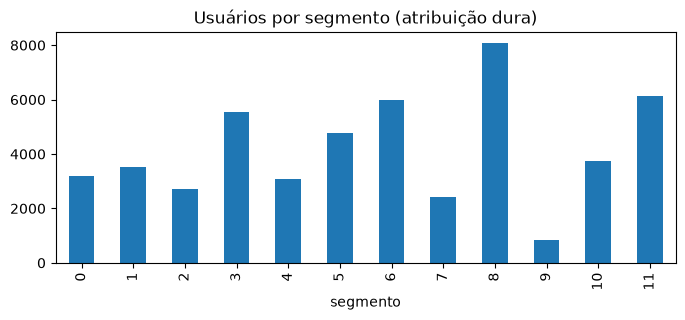

segmento dominante (prob. média máxima): 0.964


In [7]:
seg_prof['usuarios'].plot.bar(title='Usuários por segmento (atribuição dura)', figsize=(8, 3)); plt.show()
print('segmento dominante (prob. média máxima):', seg.max(axis=1).mean().round(3))

In [8]:
profiles.to_parquet('user_profiles.parquet')
seg.to_parquet('user_segments.parquet')
joblib.dump(pipe, 'gmm_users.joblib')
print(profiles.shape, seg.shape)

(50000, 20) (50000, 12)
